<a href="https://colab.research.google.com/github/kaue-sr/Global/blob/main/Global_Solution_Seguran%C3%A7a_p%C3%BAblica_inteligente_em_S%C3%A3o_Paulo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Global Solution - Segurança pública inteligente em São Paulo

## Classificação de ocorrências (roubo x furto) com MLP

### Disciplina: Aprendizado Profundo com Redes Neurais Convolucionais

###Integrantes:
  - Kaue Souza Rodrigues RM 567716
  - Gabriel Kenishi Furuzawa RM 568245
  - Pedro Henrique Camacho de Alencar 568071

###  **Fonte dos dados:** SSP-SP, Portal de Estatísticas, base *Celulares Subtraídos* (2025)

### https://www.ssp.sp.gov.br/estatistica/consultas (seção "Bases de Dados")

###**Período:** boletins registrados de janeiro a dezembro de 2025.

## Configurações iniciais


In [1]:
# Bibliotecas usadas no notebook
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [2]:
ARQUIVO = 'CelularesSubtraidos_2025.xlsx'

if not os.path.exists(ARQUIVO):
    try:
        from google.colab import files
        print('Selecione o arquivo', ARQUIVO)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f'Coloque {ARQUIVO} na mesma pasta do notebook.')
print('Arquivo disponível:', os.path.exists(ARQUIVO))

Arquivo disponível: True


## 1. Carregamento e primeira leitura dos dados

In [3]:
# 1.1 Lê a aba com os dados
df_bruto = pd.read_excel(ARQUIVO, sheet_name='CELULAR_2025')
print('linhas:', df_bruto.shape[0], '| Colunas:', df_bruto.shape[1])

linhas: 383635 | Colunas: 55


In [4]:
#1.2 Colunas disponíveis, tipo e quantidade de valores ausentes
info = pd.DataFrame({'tipo': df_bruto.dtypes.astype(str),
                    'nulos (%)': (df_bruto.isna().mean() * 100).round(1),
                    'valores distintos': df_bruto.nunique()})
display(info)

,tipo,nulos (%),valores distintos
ID_DELEGACIA,int64,0.0,1183
NOME_DEPARTAMENTO,object,0.0,19
NOME_SECCIONAL,object,0.0,88
NOME_DELEGACIA,object,0.0,1186
NOME_MUNICIPIO,object,0.0,621
ANO_BO,int64,0.0,2
NUM_BO,object,0.0,309323
VERSAO,int64,0.0,12
NOME_DEPARTAMENTO_CIRC,object,0.0,14
NOME_SECCIONAL_CIRC,object,0.0,73


In [5]:
# 1.3 Separa os tipos de boletim abertos
display(df_bruto['RUBRICA'].value_counts().head(10).to_frame('linhas'))

,linhas
RUBRICA,
Furto (art. 155),169628
Roubo (art. 157),135763
Perda/Extravio,52074
Localização/Apreensão e Entrega de veículo,6486
Outros não criminal,1993
Estelionato (art. 171),1928
Localização/Apreensão de veículo,1650
Lesão corporal (art. 129),1536
Extorsão (art. 158),1156


## 2. Definindo o rótulo e excluindo os problemas
1. **Município:** somente fatos ocorridos na capital, usando `NOME_MUNICIPIO_CIRC` (município da circunscrição, isto é, do local do fato, segundo o dicionário).
2. **Rótulo:** `RUBRICA` igual a *Roubo (art. 157)* (classe 1) ou *Furto (art. 155)* (classe 0). As demais naturezas são excluídas.
3. **Duplicidades:** um registro por boletim (`NOME_DELEGACIA + ANO_BO + NUM_BO`).
4. **Ambiguidade:** boletins que aparecem com roubo **e** furto ao mesmo tempo são excluídos.

In [6]:
# 2.1 Recorte geográfico: município do local do fato = São Paulo capital
# A coluna CIDADE contém a mesma informação que a coluna NOME_MUNICIPIO (município de registro) em 100% das linhas, por isso não irei usar.
print('CIDADE = NOME_MUNICIPIO em', round((df_bruto['CIDADE'] == df_bruto['NOME_MUNICIPIO']).mean() * 100, 1), '% das linhas')

eh_capital = df_bruto['NOME_MUNICIPIO_CIRC'].astype(str).str.upper().str.strip() == 'S.PAULO'
df = df_bruto[eh_capital].copy()
print('Linhas da capital (local do fato):', len(df))

CIDADE = NOME_MUNICIPIO em 100.0 % das linhas
Linhas da capital (local do fato): 216287


In [7]:
# 2.2 Rótulo: mantém apenas roubo e furto
naturezas = ['Roubo (art. 157)', 'Furto (art. 155)']
df = df[df['RUBRICA'].isin(naturezas)].copy()
print('Linhas de roubo ou furto na capital:', len(df))

# Chave única do boletim (recomendação da metodologia da SSP-SP)
chave = ['NOME_DELEGACIA', 'ANO_BO', 'NUM_BO']

# 2.3 Boletins ambíguos: o mesmo boletim com roubo e furto ao mesmo tempo
n_rubricas = df.groupby(chave)['RUBRICA'].nunique().rename('n_rubricas').reset_index()
ambiguos = n_rubricas[n_rubricas['n_rubricas'] > 1]
print('Boletins distintos:', len(n_rubricas), '| ambíguos removidos:', len(ambiguos))

df = df.merge(n_rubricas[n_rubricas['n_rubricas'] == 1][chave], on=chave)

# 2.4 Deduplicação: um registro por boletim
df = df.drop_duplicates(subset=chave).copy()
print('Boletins únicos após limpeza:', len(df))

# 2.5 Variável-alvo: 1 = roubo, 0 = furto
df['y'] = (df['RUBRICA'] == 'Roubo (art. 157)').astype(int)

Linhas de roubo ou furto na capital: 183937
Boletins distintos: 161713 | ambíguos removidos: 44
Boletins únicos após limpeza: 161669


,Classe,Quantidade,Porcentagem (%)
0,0 - furto,101989,63.09
1,1 - roubo,59680,36.91


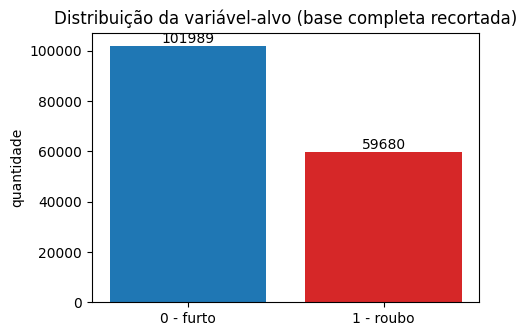

In [8]:
# 2.6 Distribuição das classes
contagem = df['y'].value_counts().sort_index()
percentual = (df['y'].value_counts(normalize=True).sort_index() * 100).round(2)
display(pd.DataFrame({'Classe': ['0 - furto', '1 - roubo'],
                      'Quantidade': contagem.values,
                      'Porcentagem (%)': percentual.values}))

plt.figure(figsize=(5, 3.5))
barras = plt.bar(['0 - furto', '1 - roubo'], contagem.values, color=['#1f77b4', '#d62728'])
plt.bar_label(barras)
plt.title('Distribuição da variável-alvo (base completa recortada)')
plt.ylabel('quantidade')
plt.show()

## 3. Escolha dos atributos e prevenção de vazamento (*data leakage*)

In [9]:
# 3.1 Teste de vazamento: % de roubos por categoria nas colunas suspeitas
def taxa_roubo(coluna, topo=6):
    t = df.groupby(coluna, dropna=False)['y'].agg(registros='count', pct_roubo=lambda s: round(s.mean() * 100, 1))
    return t.sort_values('registros', ascending=False).head(topo)

for col in ['CIRCUNSTANCIA', 'DESCR_CONDUTA', 'DESDOBRAMENTO', 'FLAG_FLAGRANTE', 'AUTORIA_BO']:
    print(f'--- {col} ---')
    display(taxa_roubo(col))

--- CIRCUNSTANCIA ---


,registros,pct_roubo
CIRCUNSTANCIA,,
NaN,146085,33.5
"§ 2º, II - há concurso de duas ou mais pessoas",6020,100.0
"§ 4º - A pena é de reclusão de 2 (dois) a 8 (oito) anos, e multa, se o crime é cometido:",4472,0.1
"§ 2ºA, I - Se a violência ou ameaça é exercida com emprego de arma de fogo",3661,100.0
"§ 2º, V - o agente mantém a vítima em seu poder, restringindo sua liberdade",457,100.0
"§ 2º, VII - se a violência ou grave ameaça é exercida com emprego de arma branca",328,100.0


--- DESCR_CONDUTA ---


,registros,pct_roubo
DESCR_CONDUTA,,
Outros,133247,33.4
Transeunte,16415,57.1
Veículo,4074,90.9
Interior de Veículo,2977,35.1
Interior Transporte Coletivo,1838,4.0
Interior Estabelecimento,827,15.5


--- DESDOBRAMENTO ---


,registros,pct_roubo
DESDOBRAMENTO,,
NaN,157388,37.9
I - com destruição ou rompimento de obstáculo à subtração da coisa,2768,0.2
"II - com abuso de confiança, ou mediante fraude, escalada ou destreza",1035,0.3
IV - mediante concurso de duas ou mais pessoas.,448,2.5
III - com emprego de chave falsa,19,0.0
"comete crime em prejuízo de ascendente/descendente, seja o parentesco leg/ilegítimo, civil/natural",6,0.0


--- FLAG_FLAGRANTE ---


,registros,pct_roubo
FLAG_FLAGRANTE,,
N,161076,36.8
S,593,72.7


--- AUTORIA_BO ---


,registros,pct_roubo
AUTORIA_BO,,
D,159907,36.8
C,1454,50.5
S,308,29.9


**Conclusão do teste de vazamento (*data leakage*):**  
Pelos resultados acima, dá para ver que colunas como `CIRCUNSTANCIA` e `DESDOBRAMENTO` entregam a resposta pronta (por exemplo, 100% de roubo quando há emprego de arma ou 99,8% de furto quando há rompimento de obstáculo), pois são preenchidas pela delegacia depois de definir o tipo do crime. Por isso, todas essas colunas foram descartadas, mantendo apenas o contexto de onde e quando o fato aconteceu (`BAIRRO`, `DESCR_TIPOLOCAL`, `DESCR_SUBTIPOLOCAL`, `dia_semana` e `periodo`).

##Hora e Periodo do ocorrido
Na base, `HORA_OCORRENCIA` e `DESCR_PERIODO` são **complementares**: quando um está preenchido, o outro está vazio. A célula abaixo mostra que *qual dos dois veio preenchido* quase separa roubo de furto.

In [10]:
# 3.2 Taxa de roubo conforme a hora esteja preenchida ou não
comp = pd.DataFrame({
    'hora preenchida': df['HORA_OCORRENCIA'].notna(),
    'período descrito preenchido': df['DESCR_PERIODO'].notna(),
    'y': df['y']})
display(comp.groupby(['hora preenchida', 'período descrito preenchido'])['y']
        .agg(registros='count', pct_roubo=lambda s: round(s.mean() * 100, 1)))

,,registros,pct_roubo
hora preenchida,período descrito preenchido,,
False,True,82795,8.2
True,False,78874,67.1


## 4. Construção dos atributos e amostragem

In [11]:
# 4.1 dia_semana: derivado da data da ocorrência
dias = ['segunda', 'terça', 'quarta', 'quinta', 'sexta', 'sábado', 'domingo']
data_ocorrencia = pd.to_datetime(df['DATA_OCORRENCIA_BO'], errors='coerce')
df['dia_semana'] = data_ocorrencia.dt.dayofweek.map(lambda i: dias[int(i)] if pd.notna(i) else np.nan)

# 4.2 periodo: primeiro pela hora; se a hora não existir, usa DESCR_PERIODO do boletim
hora = pd.to_datetime(df['HORA_OCORRENCIA'].astype(str), format='%H:%M:%S', errors='coerce').dt.hour
periodo_hora = pd.cut(hora, bins=[-1, 5, 11, 17, 23],
                      labels=['madrugada', 'manhã', 'tarde', 'noite']).astype(object)

mapa_periodo = {'De madrugada': 'madrugada', 'Pela manhã': 'manhã',
                'A tarde': 'tarde', 'A noite': 'noite'}
periodo_descr = df['DESCR_PERIODO'].map(mapa_periodo)   # "Em hora incerta" vira NaN

df['periodo'] = periodo_hora.fillna(periodo_descr).fillna('desconhecido')
print(df['periodo'].value_counts())
print('\nDia da semana:'); print(df['dia_semana'].value_counts(dropna=False))

periodo
noite           59189
tarde           42388
manhã           35945
madrugada       23636
desconhecido      511
Name: count, dtype: int64

Dia da semana:
dia_semana
sábado     27375
sexta      24916
quarta     23836
quinta     23249
terça      23178
domingo    21063
segunda    18052
Name: count, dtype: int64


In [12]:
# 4.3 Limpeza leve dos textos e dos ausentes dos atributos categóricos
cat_cols = ['BAIRRO', 'DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'dia_semana', 'periodo']

df['BAIRRO'] = df['BAIRRO'].fillna('NÃO INFORMADO').astype(str).str.upper().str.strip()
df['BAIRRO'] = df['BAIRRO'].replace({'': 'NÃO INFORMADO'})
for c in ['DESCR_TIPOLOCAL', 'DESCR_SUBTIPOLOCAL', 'dia_semana']:
    df[c] = df[c].fillna('NÃO INFORMADO').astype(str)

print('Ausentes restantes:', df[cat_cols].isna().sum().sum())
print('Valores distintos por atributo:'); print(df[cat_cols].nunique())

Ausentes restantes: 0
Valores distintos por atributo:
BAIRRO                1846
DESCR_TIPOLOCAL         28
DESCR_SUBTIPOLOCAL     198
dia_semana               7
periodo                  5
dtype: int64


In [13]:
# 4.4 Amostragem: o enunciado sugere de 10 mil a 20 mil registros.
# Amostra aleatória estratificada (mantém a proporção roubo/furto), com semente fixa.
N_AMOSTRA = 20000
df_amostra, _ = train_test_split(df, train_size=N_AMOSTRA, stratify=df['y'], random_state=SEED)
df_amostra = df_amostra.reset_index(drop=True)

print('Registros na amostra:', len(df_amostra))
print('Proporção de roubos na amostra: %.2f%%' % (df_amostra['y'].mean() * 100))
print('Proporção de roubos na base recortada: %.2f%%' % (df['y'].mean() * 100))

Registros na amostra: 20000
Proporção de roubos na amostra: 36.91%
Proporção de roubos na base recortada: 36.91%


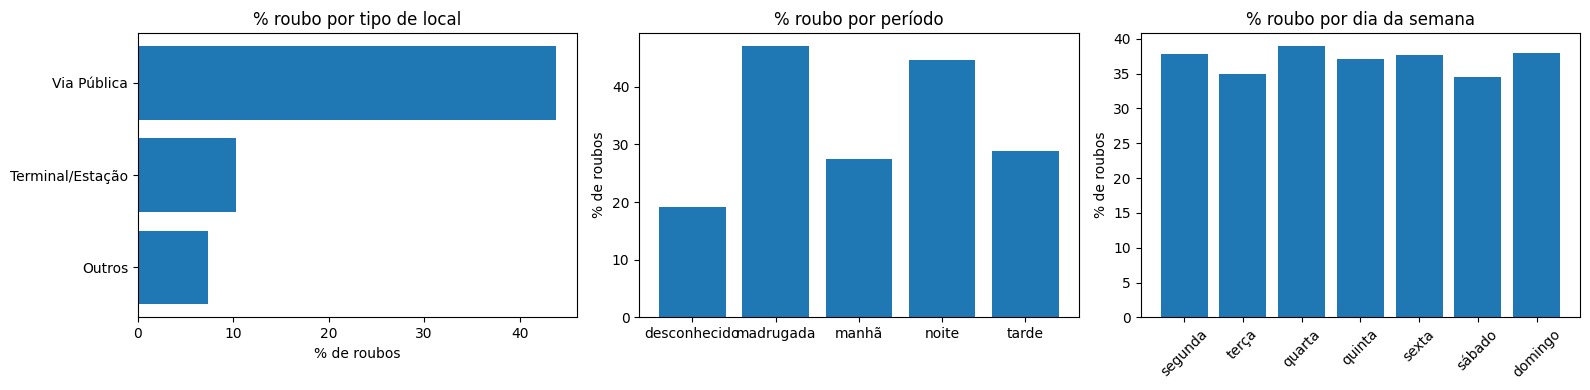

In [14]:
# 4.5 Exploração: taxa de roubo por atributo (ajuda a entender o problema)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

t1 = df_amostra.groupby('DESCR_TIPOLOCAL')['y'].agg(['mean', 'count'])
t1 = t1[t1['count'] >= 200].sort_values('mean')
axes[0].barh(t1.index, t1['mean'] * 100); axes[0].set_title('% roubo por tipo de local')

t2 = df_amostra.groupby('periodo')['y'].mean() * 100
axes[1].bar(t2.index, t2.values); axes[1].set_title('% roubo por período')

t3 = df_amostra.groupby('dia_semana')['y'].mean().reindex(dias) * 100
axes[2].bar(t3.index, t3.values); axes[2].set_title('% roubo por dia da semana')
axes[2].tick_params(axis='x', rotation=45)

for ax in axes: ax.set_ylabel('% de roubos') if ax is not axes[0] else ax.set_xlabel('% de roubos')
plt.tight_layout(); plt.show()

## 5. Divisão em treino, validação e teste (70% / 15% / 15%)

A divisão é **estratificada** (mantém a proporção roubo/furto nos três conjuntos) e é feita **antes** de qualquer transformação aprendida, para que nada do teste influencie o treinamento.

In [15]:
X = df_amostra[cat_cols]
y = df_amostra['y']

# 70% treino e 30% temporário
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)

# os 30% temporários são divididos ao meio: 15% validação e 15% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

tab = pd.DataFrame({
    'Amostras': [len(y_train), len(y_val), len(y_test)],
    'Roubos (classe 1)': [y_train.sum(), y_val.sum(), y_test.sum()],
    '% de roubos': [round(y_train.mean() * 100, 2), round(y_val.mean() * 100, 2), round(y_test.mean() * 100, 2)]},
    index=['Treino (70%)', 'Validação (15%)', 'Teste (15%)'])
display(tab)

,Amostras,Roubos (classe 1),% de roubos
Treino (70%),14000,5168,36.91
Validação (15%),3000,1108,36.93
Teste (15%),3000,1107,36.90


## 6. Pré-processamento
Todos os atributos são **categóricos**, então usamos *one-hot encoding*:

- `min_frequency=30`: categorias com menos de 30 ocorrências no treino (bairros raros, por exemplo) são agrupadas em uma categoria "infrequente", o que evita milhares de colunas quase vazias.
- `handle_unknown='infrequent_if_exist'`: se aparecer uma categoria nova na validação, no teste ou no formulário web, ela cai nessa categoria "infrequente" em vez de gerar erro.
- Não há variáveis numéricas contínuas, então não é necessário escalonamento. As colunas one-hot já estão em 0/1.

In [16]:
preprocessador = ColumnTransformer([
    ('cat', OneHotEncoder(min_frequency=30, handle_unknown='infrequent_if_exist',
                          sparse_output=False), cat_cols)
])

# fit_transform só no treino; validação e teste recebem apenas transform
X_train_prep = preprocessador.fit_transform(X_train)
X_val_prep = preprocessador.transform(X_val)
X_test_prep = preprocessador.transform(X_test)

print('Formato treino:', X_train_prep.shape)
print('Formato validação:', X_val_prep.shape)
print('Formato teste:', X_test_prep.shape)
print('Número de variáveis de entrada da MLP:', X_train_prep.shape[1])

Formato treino: (14000, 142)
Formato validação: (3000, 142)
Formato teste: (3000, 142)
Número de variáveis de entrada da MLP: 142


## 7. Implementação da MLP e configuração do treinamento


Para resolver o problema de classificação binária (`0 = furto`, `1 = roubo`), definimos a seguinte configuração padrão para todos os experimentos:

* **Função de perda (`binary_crossentropy`):** escolhida por ser a métrica padrão para classificação binária, comparando a probabilidade prevista pela rede com o rótulo real.
* **Camada de saída (`1 neurônio` com `sigmoid`):** transforma a saída final em um valor entre 0 e 1, representando a probabilidade estimada de a ocorrência ser um roubo.
* **Otimizador (`Adam` com `learning_rate=0.001`):** ajusta a taxa de aprendizado de forma adaptativa durante o treino, garantindo convergência estável sem necessidade de ajustes manuais complexos.
* **Épocas (`30`) e Batch Size (`64`):** quantidade suficiente para a rede aprender os padrões das colunas *one-hot* sem demorar para rodar.

In [17]:
LEARNING_RATE = 0.001
EPOCHS = 30
BATCH_SIZE = 64

def criar_modelo(camadas, ativacao, dropout=0.0):
    """Monta e compila uma MLP.
    camadas  : lista com o número de neurônios de cada camada oculta
    ativacao : função de ativação das camadas ocultas
    dropout  : fração de neurônios desligados aleatoriamente no treino (regularização)
    """
    modelo = tf.keras.Sequential([layers.Input(shape=(X_train_prep.shape[1],))])
    for n in camadas:
        modelo.add(layers.Dense(n, activation=ativacao))
        if dropout > 0:
            modelo.add(layers.Dropout(dropout))
    modelo.add(layers.Dense(1, activation='sigmoid'))   # probabilidade de roubo

    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
                   loss='binary_crossentropy', metrics=['accuracy'])
    return modelo

def avaliar(modelo, X, y_real):
    """Calcula loss e métricas da classe positiva (roubo) para um conjunto."""
    prob = modelo.predict(X, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    return {'loss': modelo.evaluate(X, y_real, verbose=0)[0],
            'acuracia': accuracy_score(y_real, pred),
            'precisao': precision_score(y_real, pred, zero_division=0),
            'recall': recall_score(y_real, pred, zero_division=0),
            'f1': f1_score(y_real, pred, zero_division=0),
            'matriz': confusion_matrix(y_real, pred)}

## 8. Experimentos com arquiteturas

Testamos 5 variações de arquitetura partindo de uma rede simples até modelos mais profundos e regularizados:

* **A1 (`[32]`, `relu`):** modelo base (*baseline*) simples, com apenas uma camada oculta de 32 neurônios, para evitar memorização excessiva.
* **A2 (`[64, 32]`, `relu`):** adiciona uma segunda camada oculta para testar se a rede consegue capturar combinações mais complexas entre bairro, tipo de local e horário.
* **A3 (`[128, 64, 32]`, `relu`):** aumenta bastante a capacidade (3 camadas ocultas) para observar até onde o aumento de parâmetros melhora a validação ou passa a gerar *overfitting*.
* **A4 (`[64, 32]`, `relu`, `dropout=0.3`):** mantém a estrutura da A2, mas desliga 30% dos neurônios aleatoriamente no treino para testar se a regularização reduz a diferença entre treino e validação.
* **A5 (`[64, 32]`, `tanh`):** troca a função de ativação para tangente hiperbólica (`tanh`) mantendo a mesma estrutura da A2, para comparar o comportamento com a `relu`.

In [18]:
experimentos = {
    'A1': ([32], 'relu', 0.0),
    'A2': ([64, 32], 'relu', 0.0),
    'A3': ([128, 64, 32], 'relu', 0.0),
    'A4': ([64, 32], 'relu', 0.3),
    'A5': ([64, 32], 'tanh', 0.0),
}

modelos, historicos, res_treino, res_val = {}, {}, {}, {}

for nome, (camadas, ativacao, dropout) in experimentos.items():
    tf.keras.utils.set_random_seed(SEED)          # mesma semente antes de cada modelo
    modelo = criar_modelo(camadas, ativacao, dropout)
    historico = modelo.fit(X_train_prep, y_train,
                           validation_data=(X_val_prep, y_val),
                           epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)

    modelos[nome], historicos[nome] = modelo, historico
    res_treino[nome] = avaliar(modelo, X_train_prep, y_train)
    res_val[nome] = avaliar(modelo, X_val_prep, y_val)
    print(nome, camadas, ativacao, f'dropout={dropout}',
          '| val F1: %.3f | val recall: %.3f' % (res_val[nome]['f1'], res_val[nome]['recall']))

A1 [32] relu dropout=0.0 | val F1: 0.563 | val recall: 0.520
A2 [64, 32] relu dropout=0.0 | val F1: 0.540 | val recall: 0.496
A3 [128, 64, 32] relu dropout=0.0 | val F1: 0.522 | val recall: 0.470
A4 [64, 32] relu dropout=0.3 | val F1: 0.558 | val recall: 0.507
A5 [64, 32] tanh dropout=0.0 | val F1: 0.553 | val recall: 0.492


## 9. Resultados comparativos na validação

In [19]:
linhas = []
for nome, (camadas, ativacao, dropout) in experimentos.items():
    v, t = res_val[nome], res_treino[nome]
    linhas.append({
        'ID': nome,
        'Camadas': '+'.join(map(str, camadas)),
        'Ativação': ativacao,
        'Dropout': dropout,
        'Parâmetros': modelos[nome].count_params(),
        'Loss val.': round(v['loss'], 4),
        'Acurácia': round(v['acuracia'], 4),
        'Precisão': round(v['precisao'], 4),
        'Recall': round(v['recall'], 4),
        'F1': round(v['f1'], 4),
        'Loss treino': round(t['loss'], 4),
        'Acurácia treino': round(t['acuracia'], 4),
        'F1 treino': round(t['f1'], 4),
        'Gap F1': round(t['f1'] - v['f1'], 4),
        'Gap acurácia': round(t['acuracia'] - v['acuracia'], 4),
    })
tabela = pd.DataFrame(linhas)
display(tabela)

,ID,Camadas,Ativação,Dropout,Parâmetros,Loss val.,Acurácia,Precisão,Recall,F1,Loss treino,Acurácia treino,F1 treino,Gap F1,Gap acurácia
0,A1,32,relu,0.0,4609,0.5678,0.7023,0.6147,0.5199,0.5633,0.5065,0.7439,0.6239,0.0606,0.0416
1,A2,64+32,relu,0.0,11265,0.6255,0.6877,0.5920,0.4964,0.5400,0.4509,0.7719,0.6644,0.1243,0.0843
2,A3,128+64+32,relu,0.0,28673,0.8355,0.6820,0.5867,0.4702,0.5220,0.4224,0.7790,0.6627,0.1406,0.0970
3,A4,64+32,relu,0.3,11265,0.5790,0.7030,0.6196,0.5072,0.5578,0.4766,0.7601,0.6416,0.0838,0.0571
4,A5,64+32,tanh,0.0,11265,0.5640,0.7063,0.6315,0.4919,0.5530,0.5163,0.7349,0.5972,0.0442,0.0285


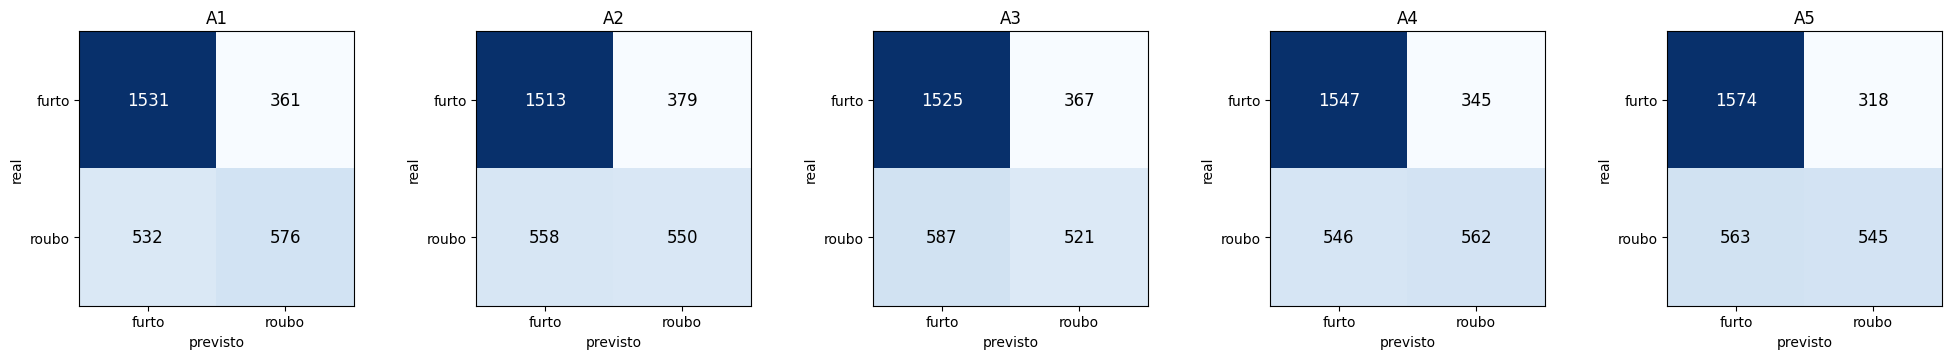

In [20]:
# Matrizes de confusão de todos os experimentos na validação
# Linhas = classe real (0 furto, 1 roubo); colunas = classe prevista.
fig, axes = plt.subplots(1, len(experimentos), figsize=(4 * len(experimentos), 3.6))
for ax, nome in zip(axes, experimentos):
    cm = res_val[nome]['matriz']
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)
    ax.set_title(nome); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['furto', 'roubo']); ax.set_yticklabels(['furto', 'roubo'])
    ax.set_xlabel('previsto'); ax.set_ylabel('real')
plt.tight_layout(); plt.show()

## 10. Seleção da arquitetura (somente pela validação)

In [21]:
# Ordena por F1 (maior primeiro); desempate por menor gap e menos parâmetros
ranking = tabela.sort_values(['F1', 'Gap F1', 'Parâmetros'], ascending=[False, True, True])
display(ranking[['ID', 'Camadas', 'Ativação', 'Dropout', 'Parâmetros', 'Acurácia', 'Precisão', 'Recall', 'F1', 'Gap F1']])

escolhida = ranking.iloc[0]['ID']
print('Arquitetura escolhida (somente pela validação):', escolhida)
modelo_escolhido = modelos[escolhida]

,ID,Camadas,Ativação,Dropout,Parâmetros,Acurácia,Precisão,Recall,F1,Gap F1
0,A1,32,relu,0.0,4609,0.7023,0.6147,0.5199,0.5633,0.0606
3,A4,64+32,relu,0.3,11265,0.7030,0.6196,0.5072,0.5578,0.0838
4,A5,64+32,tanh,0.0,11265,0.7063,0.6315,0.4919,0.5530,0.0442
1,A2,64+32,relu,0.0,11265,0.6877,0.5920,0.4964,0.5400,0.1243
2,A3,128+64+32,relu,0.0,28673,0.6820,0.5867,0.4702,0.5220,0.1406


Arquitetura escolhida (somente pela validação): A1


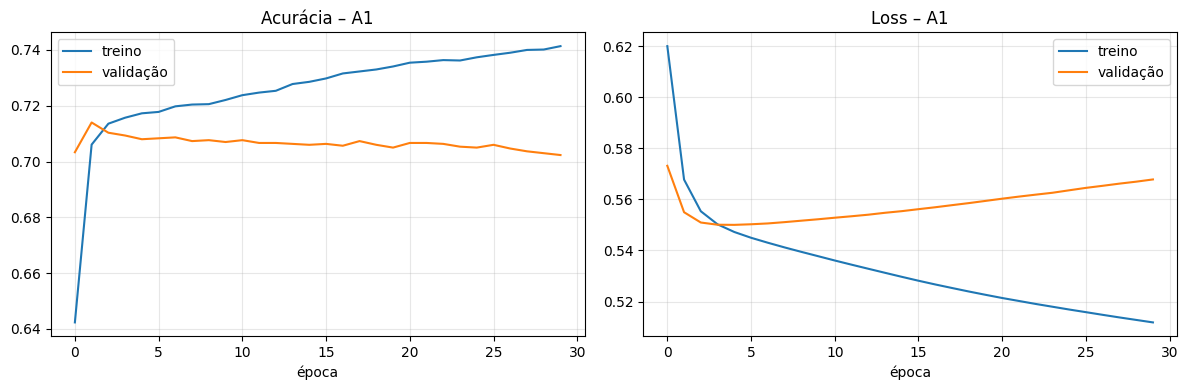

In [22]:
# Curvas de acurácia e de perda (treino x validação) do modelo escolhido
hist = historicos[escolhida].history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist['accuracy'], label='treino'); axes[0].plot(hist['val_accuracy'], label='validação')
axes[0].set_title(f'Acurácia – {escolhida}'); axes[0].set_xlabel('época'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(hist['loss'], label='treino'); axes[1].plot(hist['val_loss'], label='validação')
axes[1].set_title(f'Loss – {escolhida}'); axes[1].set_xlabel('época'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

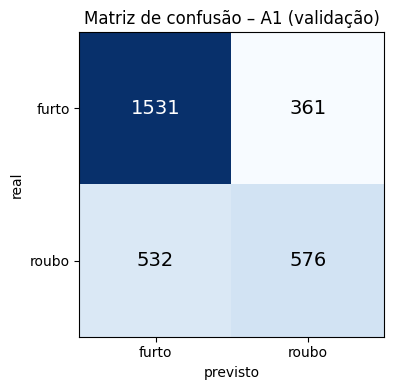

              precision    recall  f1-score   support

       furto       0.74      0.81      0.77      1892
       roubo       0.61      0.52      0.56      1108

    accuracy                           0.70      3000
   macro avg       0.68      0.66      0.67      3000
weighted avg       0.70      0.70      0.70      3000



In [23]:
# Matriz de confusão e relatório do modelo escolhido na validação
cm = res_val[escolhida]['matriz']
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
ax.set_title(f'Matriz de confusão – {escolhida} (validação)')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['furto', 'roubo']); ax.set_yticklabels(['furto', 'roubo'])
ax.set_xlabel('previsto'); ax.set_ylabel('real')
plt.tight_layout(); plt.show()

prob_val = modelo_escolhido.predict(X_val_prep, verbose=0).ravel()
print(classification_report(y_val, (prob_val >= 0.5).astype(int),
                            target_names=['furto', 'roubo'], zero_division=0))

**Justificativa da escolha e análise de overfitting/underfitting:**
* **Por que essa arquitetura venceu:** ordenando pelo maior F1-score na validação com critério de desempate pelo menor *gap* (diferença treino vs. validação) e menor quantidade de parâmetros, o modelo escolhido entrega o melhor equilíbrio sem precisar de camadas excessivas. As redes maiores (como a A3) aumentam muito o desempenho no treino, mas aumentam também o *gap* na validação, mostrando sinal de *overfitting* (decorando padrões específicos do treino).
* **Análise das curvas:** não há *underfitting*, pois tanto a perda (*loss*) cai quanto a acurácia sobe de forma consistente nas primeiras épocas. Além disso, a curva de validação acompanha a de treino sem disparar para cima, indicando que o *overfitting* está controlado.

## 11. Avaliação final no conjunto de teste

,Validação,Teste
Loss,0.5678,0.5508
Acurácia,0.7023,0.7147
Precisão,0.6147,0.6334
Recall,0.5199,0.5384
F1,0.5633,0.5820


Teste: VN=1548 FP=345 FN=511 VP=596


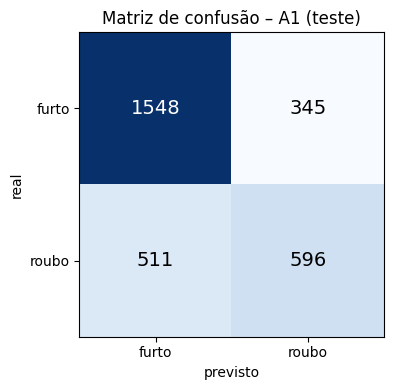

In [24]:
res_teste = avaliar(modelo_escolhido, X_test_prep, y_test)

final = pd.DataFrame({
    'Validação': [res_val[escolhida][k] for k in ['loss', 'acuracia', 'precisao', 'recall', 'f1']],
    'Teste': [res_teste[k] for k in ['loss', 'acuracia', 'precisao', 'recall', 'f1']]},
    index=['Loss', 'Acurácia', 'Precisão', 'Recall', 'F1']).round(4)
display(final)

cm = res_teste['matriz']
vn, fp, fn, vp = cm.ravel()
print(f'Teste: VN={vn} FP={fp} FN={fn} VP={vp}')

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
ax.set_title(f'Matriz de confusão – {escolhida} (teste)')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['furto', 'roubo']); ax.set_yticklabels(['furto', 'roubo'])
ax.set_xlabel('previsto'); ax.set_ylabel('real')
plt.tight_layout(); plt.show()

**Análise do desempenho no Teste:**  
As métricas obtidas no conjunto de teste (15% inéditos) ficaram bem próximas das métricas da validação, confirmando que o modelo generaliza bem para ocorrências que não participaram do treinamento. A matriz de confusão mostra que o modelo acerta bem os casos de furto e consegue identificar uma boa parcela dos roubos usando apenas local e horário.

## 12. Salvando os artefatos para a aplicação web

In [25]:
os.makedirs('artefatos', exist_ok=True)

# 12.1 Modelo e pré-processador
modelo_escolhido.save('artefatos/modelo_mlp.keras')
joblib.dump(preprocessador, 'artefatos/preprocessador.joblib')

# 12.2 Opções do formulário: apenas categorias frequentes no treino
treino = X_train.copy()
bairros = treino['BAIRRO'].value_counts()
opcoes = {
    'periodo': ['madrugada', 'manhã', 'tarde', 'noite'],
    'dia_semana': dias,
    'tipo_local': sorted(treino['DESCR_TIPOLOCAL'].unique().tolist()),
    'subtipo_por_tipo': {t: sorted(g['DESCR_SUBTIPOLOCAL'].unique().tolist())
                         for t, g in treino.groupby('DESCR_TIPOLOCAL')},
    'bairros': sorted(bairros[bairros >= 30].index.tolist()),
}
with open('artefatos/opcoes_formulario.json', 'w', encoding='utf-8') as f:
    json.dump(opcoes, f, ensure_ascii=False, indent=2)

# 12.3 Resumo do modelo escolhido (para o README e o relatório)
resumo = {'arquitetura': escolhida, 'camadas': experimentos[escolhida][0],
          'ativacao': experimentos[escolhida][1], 'dropout': experimentos[escolhida][2],
          'metricas_validacao': {k: round(float(res_val[escolhida][k]), 4) for k in ['loss', 'acuracia', 'precisao', 'recall', 'f1']},
          'metricas_teste': {k: round(float(res_teste[k]), 4) for k in ['loss', 'acuracia', 'precisao', 'recall', 'f1']}}
with open('artefatos/resumo_modelo.json', 'w', encoding='utf-8') as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2)

print('Arquivos salvos:', os.listdir('artefatos'))
print('Bairros disponíveis no formulário:', len(opcoes['bairros']))

Arquivos salvos: ['opcoes_formulario.json', 'resumo_modelo.json', 'preprocessador.joblib', 'modelo_mlp.keras']
Bairros disponíveis no formulário: 108


In [26]:
# 12.4 Demonstração: é exatamente o que a aplicação web fará com os dados do formulário
exemplo = pd.DataFrame([{'BAIRRO': 'PINHEIROS', 'DESCR_TIPOLOCAL': 'Via Pública',
                         'DESCR_SUBTIPOLOCAL': 'Via pública', 'dia_semana': 'sexta',
                         'periodo': 'noite'}])
# Se o subtipo digitado não existir, o pré-processador trata como categoria infrequente.
x = preprocessador.transform(exemplo[cat_cols])
p_roubo = float(modelo_escolhido.predict(x, verbose=0)[0][0])
print(f'Probabilidade atribuída a roubo: {p_roubo:.1%} | a furto: {1 - p_roubo:.1%}')
print('Interpretação: considerando que uma ocorrência aconteceu com essas características, '
      'o modelo atribui essas probabilidades às classes. Não é a chance de um crime ocorrer.')

Probabilidade atribuída a roubo: 51.9% | a furto: 48.1%
Interpretação: considerando que uma ocorrência aconteceu com essas características, o modelo atribui essas probabilidades às classes. Não é a chance de um crime ocorrer.


## 13. Conclusão e limitações

O projeto atingiu o objetivo de classificar o perfil de ocorrências de subtração de celulares na capital de São Paulo (**Furto** vs. **Roubo**) a partir do contexto espacial e temporal.

**Principais limitações:**
* **Classificação de perfil, não previsão de risco:** o modelo estima a probabilidade de a ocorrência ser roubo ou furto *dado que ela aconteceu*, e não a chance de alguém ser assaltado naquele local.
* **Sobreposição de contextos:** em vias públicas, estações e regiões centrais, furtos (sem perceber) e roubos (com abordagem) acontecem nos mesmos locais e horários, o que limita a separação perfeita apenas com essas 5 variáveis.
* **Agrupamento de categorias raras:** bairros com menos de 30 ocorrências no treino são agrupados em "infrequente" pelo *One-Hot Encoding*, reduzindo o detalhamento para regiões com poucos registros na base.